# NEURANUM v2.1 — Physics-Informed Neural Network (PINN) Colab Template

Track: **8-Ion Multicomponent Nernst–Planck + Donnan Corpus**

Before running:
1. In NEURANUM, open the **All Datasets** tab and click **8-Ion PINN Bundle (.zip)** (`neuranum_pinn_8ion_verified_316_runs.zip`) for 8-ion training, or **Download All Datasets (.zip)** (`neuranum_all_datasets_v2.1.0.zip`) if you also want Stage 1 binary NaCl.
2. Upload that `.zip` file to Google Drive (`MyDrive/` or `MyDrive/NEURANUM/`).
3. Set Colab Runtime to **T4 / L4 / A100 GPU**.


## 01. Google Colab GPU Setup, Drive Mount & Fast SSD Unzip
Extracting the compressed archive to local /content SSD eliminates Drive FUSE latency during PyTorch minibatch loading.


In [7]:
# Cell 1 — Google Colab GPU Check, Drive Mount & Auto-Unzip
from google.colab import drive
import glob, os, subprocess, torch

drive.mount('/content/drive')

# Search Google Drive for NEURANUM dataset archives (supports Part 1 + Part 2 split or single archive)
part_zips = sorted(glob.glob('/content/drive/MyDrive/**/neuranum_pinn_8ion_part*.zip', recursive=True))
if part_zips:
    zip_list = part_zips
else:
    CANDIDATES = [
        '/content/drive/MyDrive/NEURANUM/neuranum_pinn_8ion_verified_316_runs.zip',
        '/content/drive/MyDrive/NEURANUM/neuranum_all_datasets_v2.1.0.zip',
        '/content/drive/MyDrive/NEURANUM/neuranum_data.zip',
        '/content/drive/MyDrive/neuranum_pinn_8ion_verified_316_runs.zip',
        '/content/drive/MyDrive/neuranum_all_datasets_v2.1.0.zip',
    ]
    zip_list = [p for p in CANDIDATES if os.path.exists(p)]
    if not zip_list:
        zip_list = sorted(glob.glob('/content/drive/MyDrive/**/neuranum*.zip', recursive=True))[:1]

if not zip_list:
    raise FileNotFoundError(
        "No NEURANUM .zip found in Google Drive. Open NEURANUM -> 'All Datasets' -> download "
        "Part 1 + Part 2 (or 8-Ion PINN Bundle) and upload to MyDrive/NEURANUM/."
    )

os.makedirs('/content/neuranum', exist_ok=True)
for zp in zip_list:
    print("Extracting dataset archive:", zp)
    subprocess.run(['unzip', '-q', '-o', zp, '-d', '/content/neuranum'], check=True)
subprocess.run(['pip', '-q', 'install', 'torch', 'numpy', 'pandas', 'scikit-learn', 'matplotlib'], check=True)

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting dataset archive: /content/drive/MyDrive/neuranum_pinn_8ion_part1_001_140.zip
Extracting dataset archive: /content/drive/MyDrive/neuranum_pinn_8ion_part2_141_275.zip
CUDA available: True
Device: Tesla T4


## 02. Case-Level Dataset Loader (8-Ion Sobol Corpus)
Reads converged 8-ion .npz fields (50x20 per channel), maps coordinates to [0, 1]^2, and computes per-species inlet normalization scales.


In [8]:
# Cell 2 — Case-Level Dataset Loader (8-Ion Multicomponent Corpus)
# IMPORTANT: Always split by case_id (never by random (x, y) nodes) to prevent data leakage.
import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

DATA_DIR = "/content/neuranum/data/pinn_8ion_sobol"
SPECIES = ["Na", "K", "Mg", "Ca", "Cl", "SO4", "HCO3", "CO3"]
PARAM_COLS = [
    "conc_Na_mol_m3", "conc_K_mol_m3", "conc_Mg_mol_m3", "conc_Ca_mol_m3",
    "conc_Cl_mol_m3", "conc_SO4_mol_m3", "conc_HCO3_mol_m3", "conc_CO3_mol_m3",
    "c_dil_inlet_mol_m3", "pH", "temperature_K",
    "u_mean_conc_m_s", "u_mean_dil_m_s",
    "channel_height_um", "channel_length_cm",
    "X_cem_mol_m3", "X_aem_mol_m3", "load_fraction",
]

meta = pd.read_csv(os.path.join(DATA_DIR, "case_metadata.csv"))
meta = meta[meta["converged"].astype(str).str.lower() == "true"].copy()
meta = meta[
    (meta["mass_balance_rel_err_conc"] < 0.02) &
    (meta["mass_balance_rel_err_dil"] < 0.02)
].copy()
meta["npz_path"] = meta["case_id"].apply(
    lambda cid: os.path.join(DATA_DIR, "generated", f"{cid}_fields.npz")
)
# Filter to .npz files actually present on disk (86 converged files in default export, or 275 if regenerated)
meta = meta[meta["npz_path"].apply(os.path.exists)].reset_index(drop=True)
print(f"Verified 8-ion cases available on disk: {len(meta)}")

# 70% Train / 15% Val / 15% Test split by case_id
train_df, tmp_df = train_test_split(meta, test_size=0.30, random_state=42)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, random_state=42)

param_scaler = StandardScaler().fit(train_df[PARAM_COLS].values)


class Neuranum8IonDataset(Dataset):
    def __init__(self, df: pd.DataFrame, scaler: StandardScaler):
        self.records = []
        params_scaled = scaler.transform(df[PARAM_COLS].values).astype(np.float32)

        for idx, (_, row) in enumerate(df.iterrows()):
            npz = np.load(row["npz_path"])
            L = float(row["channel_length_cm"]) * 1e-2   # m
            h = float(row["channel_height_um"]) * 1e-6   # m
            T = float(row["temperature_K"])
            u_conc = float(row["u_mean_conc_m_s"])
            u_dil = float(row["u_mean_dil_m_s"])

            # Known inlet vectors from PARAM_COLS (zero test-set leakage)
            c_in_conc = np.array([float(row[f"conc_{sp}_mol_m3"]) for sp in SPECIES], dtype=np.float32)
            c_dil_0 = float(row["c_dil_inlet_mol_m3"])
            c_in_dil = np.array([c_dil_0, 0.0, 0.0, 0.0, c_dil_0, 0.0, 0.0, 0.0], dtype=np.float32)

            for ch_flag, suffix, u_bar, c_inlet in [
                (1.0, "conc", u_conc, c_in_conc),
                (0.0, "dil", u_dil, c_in_dil),
            ]:
                # Channel-aware O(1) scale so LC trace ions are not dwarfed by HC inlet concentrations
                if ch_flag > 0.5:
                    c_scale = np.maximum(c_in_conc, 1e-2)
                else:
                    c_scale = np.maximum(c_in_dil, np.maximum(0.15 * c_in_conc, 1e-2))

                xg = npz[f"x_{suffix}"].astype(np.float32)
                yg = npz[f"y_{suffix}"].astype(np.float32)
                x_tilde = (xg / L).reshape(-1)
                # Subtract yg.min() so both local [0, h] and global [h, 2h] grids map cleanly to [0, 1]
                y_tilde = ((yg - yg.min()) / h).reshape(-1)

                c_mat = np.stack(
                    [npz[f"c_{sp}_{suffix}"].reshape(-1) for sp in SPECIES], axis=-1
                ).astype(np.float32)
                phi = npz[f"phi_{suffix}"].reshape(-1).astype(np.float32)
                j_cem = np.stack([npz[f"J_cem_{sp}"] for sp in SPECIES], axis=-1).astype(np.float32)
                j_aem = np.stack([npz[f"J_aem_{sp}"] for sp in SPECIES], axis=-1).astype(np.float32)

                n_pts = x_tilde.shape[0]
                self.records.append({
                    "case_id": row["case_id"],
                    "xy_tilde": np.stack([x_tilde, y_tilde], axis=-1),
                    "ch_flag": np.full((n_pts, 1), ch_flag, dtype=np.float32),
                    "params_norm": np.repeat(params_scaled[idx:idx+1], n_pts, axis=0),
                    "c_true": c_mat,
                    "c_inlet": np.repeat(c_inlet[None, :], n_pts, axis=0),
                    "c_scale": np.repeat(c_scale[None, :], n_pts, axis=0),
                    "phi_true": phi[:, None],
                    "L": np.full((n_pts, 1), L, dtype=np.float32),
                    "h": np.full((n_pts, 1), h, dtype=np.float32),
                    "T": np.full((n_pts, 1), T, dtype=np.float32),
                    "u_bar": np.full((n_pts, 1), u_bar, dtype=np.float32),
                    "j_cem_wall": j_cem,
                    "j_aem_wall": j_aem,
                })

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        return self.records[i]

Verified 8-ion cases available on disk: 275


## 03. Fourier-Feature SiLU Parametric PINN Network
Uses smooth SiLU activations (required for non-zero d2c/dy2) and positive Softplus outputs to guarantee c_k > 0.


In [9]:
# Cell 3 — Smooth Hard-Inlet Fourier-SiLU Parametric PINN Architecture
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class FourierRedPINN(nn.Module):
    """
    Parametric 2D Steady-State RED PINN with Hard Inlet Boundary Encoding.
    - Combines raw (x_tilde, y_tilde) with low-frequency Fourier features (sigma=1.2) to avoid
      high-frequency ringing and 2nd-derivative explosions when generalizing across 18D Sobol runs.
    - Hard-encodes exact inlet concentrations c(0, y) = c_inlet so the network only learns
      axial/transverse concentration polarization rather than memorizing 18D inlet baselines.
    - SiLU activation preserves smooth C-infinity second derivatives (never use ReLU or Dropout).
    """
    def __init__(self, param_dim: int, n_species: int = 8, hidden: int = 128, layers: int = 4, fourier_dim: int = 16):
        super().__init__()
        self.register_buffer("B", torch.randn(2, fourier_dim) * 1.2)
        in_dim = 2 + 2 * fourier_dim + 1 + param_dim  # (x,y) + Fourier(x,y) + ch_flag + params

        blocks = [nn.Linear(in_dim, hidden), nn.SiLU()]
        for _ in range(layers - 1):
            blocks.extend([nn.Linear(hidden, hidden), nn.SiLU()])
        self.net = nn.Sequential(*blocks)

        self.conc_head = nn.Linear(hidden, n_species)
        self.phi_head = nn.Linear(hidden, 1)

    def forward(
        self,
        xy_tilde: torch.Tensor,
        ch_flag: torch.Tensor,
        params_norm: torch.Tensor,
        c_inlet: torch.Tensor | None = None,
        c_scale: torch.Tensor | None = None,
    ):
        proj = 2.0 * torch.pi * (xy_tilde @ self.B)
        feat = torch.cat([xy_tilde, torch.sin(proj), torch.cos(proj), ch_flag, params_norm], dim=-1)
        h = self.net(feat)
        delta = self.conc_head(h)
        phi_tilde = self.phi_head(h)

        if c_inlet is not None and c_scale is not None:
            alpha = c_inlet / torch.clamp(c_scale, min=1e-6)
            x_t = xy_tilde[:, 0:1]
            alpha_pos = torch.clamp(alpha, min=1e-4)
            inv_sp = torch.where(
                alpha_pos > 20.0,
                alpha_pos,
                torch.log(torch.expm1(alpha_pos)),
            )
            c_from_pos = F.softplus(inv_sp + x_t * delta)
            c_from_zero = x_t * F.softplus(delta)
            c_tilde = torch.where(alpha > 0.0, c_from_pos, c_from_zero)
        else:
            c_tilde = F.softplus(delta, beta=2.0) + 1e-6

        return c_tilde, phi_tilde

## 04. Nernst–Planck, Electroneutrality & Potential Closure Loss Functions
Implements exact autograd chain-rule derivatives on xy_tilde, analytical Poiseuille u(y), electroneutrality residual, elliptic potential closure, and outlet zero-gradient BCs.


In [10]:
# Cell 4 — Nernst-Planck, Electroneutrality, Potential Closure & Boundary Loss Functions
import torch
import torch.nn.functional as F

R_GAS = 8.314462618
FARADAY = 96485.33212
MU_25C = 8.90e-4

# Species order matching NEURANUM: [Na+, K+, Mg2+, Ca2+, Cl-, SO4^2-, HCO3-, CO3^2-]
Z_VALS = torch.tensor([1.0, 1.0, 2.0, 2.0, -1.0, -2.0, -1.0, -2.0], device=DEVICE)
D_25C = torch.tensor(
    [1.334e-9, 1.960e-9, 0.705e-9, 0.792e-9, 2.032e-9, 1.070e-9, 1.180e-9, 0.955e-9],
    device=DEVICE,
)

def stokes_einstein_diffusivities(T_K: torch.Tensor) -> torch.Tensor:
    """Vogel viscosity + Stokes-Einstein diffusivity scaling D_k(T) matching lib/multicomponentSolver2d.ts."""
    mu_eff = MU_25C * torch.exp(578.919 * (1.0 / (T_K - 137.546) - 1.0 / (298.15 - 137.546)))
    factor = (T_K / 298.15) * (MU_25C / mu_eff)
    return factor * D_25C.unsqueeze(0)  # (N, 8)

def grad_1st(y: torch.Tensor, x: torch.Tensor) -> torch.Tensor:
    return torch.autograd.grad(
        y, x, grad_outputs=torch.ones_like(y), create_graph=True, retain_graph=True
    )[0]

def compute_nernst_planck_losses(
    model: nn.Module,
    xy_tilde: torch.Tensor,     # (N, 2) in [0, 1]^2, requires_grad=True
    ch_flag: torch.Tensor,      # (N, 1), 1.0=HC, 0.0=LC
    params_norm: torch.Tensor,  # (N, 18)
    c_inlet: torch.Tensor,      # (N, 8) channel inlet [mol/m^3]
    c_scale: torch.Tensor,      # (N, 8) channel-aware normalization scale [mol/m^3]
    L: torch.Tensor,            # (N, 1) channel length [m]
    h: torch.Tensor,            # (N, 1) channel height [m]
    T_K: torch.Tensor,          # (N, 1) temperature [K]
    u_bar: torch.Tensor,        # (N, 1) mean channel velocity [m/s]
    c_true: torch.Tensor | None = None,
    phi_true: torch.Tensor | None = None,
):
    xy_tilde = xy_tilde.clone().detach().requires_grad_(True)
    c_tilde, phi_tilde = model(xy_tilde, ch_flag, params_norm, c_inlet, c_scale)

    # Physical units
    c = c_tilde * c_scale                       # [mol/m^3]
    V_T = (R_GAS * T_K) / FARADAY               # Thermal voltage RT/F [V]
    phi = phi_tilde * V_T                       # [V]
    D_k = stokes_einstein_diffusivities(T_K)    # [m^2/s]

    # Analytical plane Poiseuille velocity u(y_tilde) = 6 * u_bar * y_tilde * (1 - y_tilde), v = 0
    y_t = xy_tilde[:, 1:2]
    u_y = 6.0 * u_bar * y_t * (1.0 - y_t)       # [m/s]

    # Potential gradients (chain rule from dimensionless xy_tilde to physical x, y)
    dphi_dxy = grad_1st(phi, xy_tilde)
    dphi_dx = dphi_dxy[:, 0:1] / L
    dphi_dy = dphi_dxy[:, 1:2] / h

    d2phi_dx2 = grad_1st(dphi_dxy[:, 0:1], xy_tilde)[:, 0:1] / (L ** 2)
    d2phi_dy2 = grad_1st(dphi_dxy[:, 1:2], xy_tilde)[:, 1:2] / (h ** 2)

    np_residuals = []
    sum_z_D_lap_c = torch.zeros_like(phi)
    kappa = torch.zeros_like(phi)

    for k in range(8):
        ck = c[:, k:k+1]
        zk = Z_VALS[k]
        Dk = D_k[:, k:k+1]

        dc_dxy = grad_1st(ck, xy_tilde)
        dc_dx = dc_dxy[:, 0:1] / L
        dc_dy = dc_dxy[:, 1:2] / h

        d2c_dx2 = grad_1st(dc_dxy[:, 0:1], xy_tilde)[:, 0:1] / (L ** 2)
        d2c_dy2 = grad_1st(dc_dxy[:, 1:2], xy_tilde)[:, 1:2] / (h ** 2)

        # Steady 2D Nernst-Planck residual:
        # u(y) dc/dx - D (d2c/dx2 + d2c/dy2) - (z F / RT) D * div(c * grad(phi)) = 0
        div_mig = (
            dc_dx * dphi_dx + ck * d2phi_dx2 +
            dc_dy * dphi_dy + ck * d2phi_dy2
        )
        res_k = (
            u_y * dc_dx
            - Dk * (d2c_dx2 + d2c_dy2)
            - (zk / V_T) * Dk * div_mig
        )

        # Scale each species residual by characteristic advection rate (u_bar * c_scale / L)
        adv_scale = torch.clamp(u_bar * c_scale[:, k:k+1] / L, min=1e-6)
        np_residuals.append(res_k / adv_scale)

        # Accumulate terms for elliptic potential closure: div(kappa grad phi) + F sum z D lap(c) = 0
        kappa = kappa + (FARADAY / V_T) * (zk ** 2) * Dk * ck
        sum_z_D_lap_c = sum_z_D_lap_c + FARADAY * zk * Dk * (d2c_dx2 + d2c_dy2)

    np_cat = torch.cat(np_residuals, dim=-1)
    loss_np = F.smooth_l1_loss(np_cat, torch.zeros_like(np_cat), beta=2.0)

    # Local electroneutrality closure: sum(z_k * c_k) = 0 (strictly scaled to push residual < 1 mol/m^3)
    en_raw = torch.sum(c * Z_VALS.unsqueeze(0), dim=-1, keepdim=True)
    en_scale = torch.clamp(0.05 * torch.sum(c_scale * torch.abs(Z_VALS).unsqueeze(0), dim=-1, keepdim=True), min=5.0)
    loss_en = torch.mean((en_raw / en_scale) ** 2)

    # Elliptic liquid-junction potential residual (Huber loss prevents curvature spikes during ramp-in)
    dkappa_dxy = grad_1st(kappa, xy_tilde)
    div_kappa_grad_phi = (
        (dkappa_dxy[:, 0:1] / L) * dphi_dx
        + (dkappa_dxy[:, 1:2] / h) * dphi_dy
        + kappa * (d2phi_dx2 + d2phi_dy2)
    )
    pot_scale = torch.clamp(kappa * V_T / (h ** 2), min=1e-4)
    pot_res = (div_kappa_grad_phi + sum_z_D_lap_c) / pot_scale
    loss_pot = F.smooth_l1_loss(pot_res, torch.zeros_like(pot_res), beta=2.0)

    losses = {"np": loss_np, "en": loss_en, "pot": loss_pot}
    if c_true is not None and phi_true is not None:
        loss_data_c = F.mse_loss(c_tilde, c_true / c_scale)
        loss_data_phi = F.mse_loss(phi_tilde, phi_true / V_T)
        losses["data"] = loss_data_c + 0.5 * loss_data_phi

    return losses, c, phi

def compute_boundary_losses(
    model: nn.Module,
    xy_outlet: torch.Tensor,    # (N_out, 2) with x_tilde = 1.0
    ch_outlet: torch.Tensor,
    params_outlet: torch.Tensor,
    c_inlet_out: torch.Tensor,
    c_scale_out: torch.Tensor,
):
    """Enforce zero-gradient Neumann outlet BC: dc_k/dx = 0, dphi/dx = 0 at x_tilde = 1."""
    xy_outlet = xy_outlet.clone().detach().requires_grad_(True)
    c_tilde, phi_tilde = model(xy_outlet, ch_outlet, params_outlet, c_inlet_out, c_scale_out)

    dc_dx_norm = []
    for k in range(c_tilde.shape[1]):
        g = grad_1st(c_tilde[:, k:k+1], xy_outlet)[:, 0:1]
        dc_dx_norm.append(g)
    dphi_dx_norm = grad_1st(phi_tilde, xy_outlet)[:, 0:1]

    return torch.mean(torch.cat(dc_dx_norm, dim=-1) ** 2) + torch.mean(dphi_dx_norm ** 2)

## 05. Two-Phase Curriculum Training & Boundary-Biased Sampling
Biases 35% of collocation samples near y_tilde in [0, 0.15] U [0.85, 1.0] to capture steep CEM/AEM concentration polarization.


In [11]:
# Cell 5 — Curriculum Training Loop with Validation Checkpointing
import os as _os
import numpy as np
import torch

model = FourierRedPINN(param_dim=len(PARAM_COLS), n_species=8, hidden=128, layers=4, fourier_dim=16).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=1e-4)
EPOCHS = 4000
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

train_ds = Neuranum8IonDataset(train_df, param_scaler)
val_ds = Neuranum8IonDataset(val_df, param_scaler)

BATCH_KEYS = ["xy_tilde", "ch_flag", "params_norm", "c_true", "c_inlet", "c_scale", "phi_true", "L", "h", "T", "u_bar"]

def sample_channel_batch(dataset, n_cases=24, n_pts_per_case=128):
    idxs = np.random.choice(len(dataset), size=min(n_cases, len(dataset)), replace=False)
    batches = []
    for i in idxs:
        rec = dataset[i]
        total = rec["xy_tilde"].shape[0]
        # Bias 35% of sampled nodes near y_tilde in [0, 0.15] or [0.85, 1.0] to resolve membrane polarization
        y_vals = rec["xy_tilde"][:, 1]
        wall_mask = (y_vals <= 0.15) | (y_vals >= 0.85)
        wall_idx = np.where(wall_mask)[0]
        n_wall = int(0.35 * n_pts_per_case)
        pick_wall = np.random.choice(wall_idx, size=n_wall, replace=True)
        pick_bulk = np.random.choice(total, size=n_pts_per_case - n_wall, replace=False)
        pick = np.concatenate([pick_wall, pick_bulk])
        batches.append({k: rec[k][pick] for k in BATCH_KEYS})

    return {
        k: torch.tensor(np.concatenate([b[k] for b in batches], axis=0), device=DEVICE)
        for k in BATCH_KEYS
    }

@torch.no_grad()
def evaluate_rel_l2(dataset):
    model.eval()
    errs = []
    for rec in dataset:
        xy = torch.tensor(rec["xy_tilde"], device=DEVICE)
        ch = torch.tensor(rec["ch_flag"], device=DEVICE)
        pr = torch.tensor(rec["params_norm"], device=DEVICE)
        ci = torch.tensor(rec["c_inlet"], device=DEVICE)
        cs = torch.tensor(rec["c_scale"], device=DEVICE)
        c_tilde, _ = model(xy, ch, pr, ci, cs)
        c_pred = (c_tilde * cs).cpu().numpy()
        c_true = rec["c_true"]
        errs.append(np.linalg.norm(c_pred - c_true) / np.maximum(np.linalg.norm(c_true), 1e-12))
    return float(np.mean(errs))

CKPT_PATH = "/content/drive/MyDrive/NEURANUM/neuranum_pinn_8ion.pt"
_os.makedirs(_os.path.dirname(CKPT_PATH), exist_ok=True)
best_val_l2 = float("inf")

for epoch in range(1, EPOCHS + 1):
    model.train()
    batch = sample_channel_batch(train_ds, n_cases=24, n_pts_per_case=128)

    # Smooth curriculum ramp: 400-epoch data warmup, then 1000-epoch gradual PDE ramp
    ramp = min(1.0, max(0.0, (epoch - 400) / 1000.0))

    losses, _, _ = compute_nernst_planck_losses(
        model,
        batch["xy_tilde"], batch["ch_flag"], batch["params_norm"],
        batch["c_inlet"], batch["c_scale"], batch["L"], batch["h"], batch["T"], batch["u_bar"],
        batch["c_true"], batch["phi_true"],
    )

    # Sample outlet points (x_tilde = 1.0) for Neumann BC
    xy_out = batch["xy_tilde"][:128].clone()
    xy_out[:, 0] = 1.0
    loss_bc = compute_boundary_losses(
        model, xy_out, batch["ch_flag"][:128], batch["params_norm"][:128],
        batch["c_inlet"][:128], batch["c_scale"][:128],
    )

    total_loss = (
        2.0 * losses["data"]
        + 0.05 * ramp * losses["np"]
        + 1.00 * ramp * losses["en"]
        + 0.01 * ramp * losses["pot"]
        + 0.05 * ramp * loss_bc
    )

    optimizer.zero_grad()
    total_loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    scheduler.step()

    if epoch % 250 == 0 or epoch == 1:
        val_l2 = evaluate_rel_l2(val_ds)
        saved_tag = ""
        if val_l2 < best_val_l2 and epoch >= 400:
            best_val_l2 = val_l2
            torch.save(model.state_dict(), CKPT_PATH)
            saved_tag = " [BEST SAVED]"
        print(
            f"Epoch {epoch:4d} | Data={losses['data'].item():.3e} | NP={losses['np'].item():.3e} | "
            f"EN={losses['en'].item():.3e} | Pot={losses['pot'].item():.3e} | ValRelL2={val_l2*100:.2f}%{saved_tag}"
        )

if not _os.path.exists(CKPT_PATH):
    torch.save(model.state_dict(), CKPT_PATH)
print(f"Best Val Rel L2: {best_val_l2*100:.2f}% -> Checkpoint: {CKPT_PATH}")

Epoch    1 | Data=2.206e-01 | NP=3.367e-02 | EN=1.873e-01 | Pot=3.927e-03 | ValRelL2=20.87%
Epoch  250 | Data=9.334e-03 | NP=1.085e-01 | EN=4.298e-02 | Pot=1.959e+00 | ValRelL2=9.98%
Epoch  500 | Data=4.996e-03 | NP=6.261e-02 | EN=1.813e-02 | Pot=1.074e+00 | ValRelL2=5.62% [BEST SAVED]
Epoch  750 | Data=4.019e-03 | NP=1.670e-02 | EN=6.184e-03 | Pot=2.176e-01 | ValRelL2=5.88%
Epoch 1000 | Data=2.188e-03 | NP=1.054e-02 | EN=3.853e-03 | Pot=1.040e-01 | ValRelL2=5.24% [BEST SAVED]
Epoch 1250 | Data=3.519e-03 | NP=7.510e-03 | EN=1.518e-03 | Pot=9.412e-02 | ValRelL2=4.81% [BEST SAVED]
Epoch 1500 | Data=1.979e-03 | NP=4.859e-03 | EN=1.487e-03 | Pot=6.372e-02 | ValRelL2=4.66% [BEST SAVED]
Epoch 1750 | Data=1.506e-03 | NP=5.305e-03 | EN=1.364e-03 | Pot=4.191e-02 | ValRelL2=4.07% [BEST SAVED]
Epoch 2000 | Data=2.635e-03 | NP=1.450e-02 | EN=1.082e-02 | Pot=7.074e-02 | ValRelL2=3.94% [BEST SAVED]
Epoch 2250 | Data=9.462e-04 | NP=1.741e-03 | EN=5.845e-04 | Pot=5.283e-02 | ValRelL2=3.66% [BEST SAVED

In [12]:
import os, torch
os.makedirs("/content/drive/MyDrive/NEURANUM", exist_ok=True)
torch.save(model.state_dict(), "/content/drive/MyDrive/NEURANUM/neuranum_pinn_8ion.pt")
print("Saved successfully!")

Saved successfully!


## 06. Unseen Test-Set Physics Verification & Inference Speedup
Verifies generalization strictly on held-out case_ids and logs GPU inference speedup against the 2D finite-volume solver.


In [13]:
# Cell 6 — Unseen Test-Set Physics Verification & Inference Speedup Benchmark
import time
import numpy as np
import torch

if "model" not in globals():
    model = FourierRedPINN(param_dim=len(PARAM_COLS), n_species=8, hidden=128, layers=4, fourier_dim=16).to(DEVICE)
model.load_state_dict(torch.load("/content/drive/MyDrive/NEURANUM/neuranum_pinn_8ion.pt", map_location=DEVICE))
test_ds = Neuranum8IonDataset(test_df, param_scaler)
model.eval()

rel_l2_hc, rel_l2_lc, phi_mae_mv = [], [], []
en_errors = []
infer_times_ms = []
z_np = np.array([1, 1, 2, 2, -1, -2, -1, -2], dtype=np.float32)

for rec in test_ds:
    xy = torch.tensor(rec["xy_tilde"], device=DEVICE)
    ch = torch.tensor(rec["ch_flag"], device=DEVICE)
    pr = torch.tensor(rec["params_norm"], device=DEVICE)
    ci = torch.tensor(rec["c_inlet"], device=DEVICE)
    cs = torch.tensor(rec["c_scale"], device=DEVICE)
    V_T = (8.314462618 * rec["T"][0, 0]) / 96485.33212

    t0 = time.perf_counter()
    with torch.no_grad():
        c_tilde, phi_tilde = model(xy, ch, pr, ci, cs)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    infer_times_ms.append((time.perf_counter() - t0) * 1000.0)

    c_pred = (c_tilde * cs).cpu().numpy()
    c_true = rec["c_true"]
    rel_l2 = np.linalg.norm(c_pred - c_true) / np.maximum(np.linalg.norm(c_true), 1e-12)
    if rec["ch_flag"][0, 0] > 0.5:
        rel_l2_hc.append(rel_l2)
    else:
        rel_l2_lc.append(rel_l2)

    phi_pred_v = (phi_tilde * V_T).cpu().numpy()
    phi_mae_mv.append(np.mean(np.abs(phi_pred_v - rec["phi_true"])) * 1000.0)
    en_errors.append(np.max(np.abs(np.sum(c_pred * z_np[None, :], axis=1))))

rel_l2_all = rel_l2_hc + rel_l2_lc
print(f"Overall Mean Relative L2 Error (test): {np.mean(rel_l2_all)*100:.2f}%")
print(f"  - HC (Concentrated) Rel L2 Error:    {np.mean(rel_l2_hc)*100:.2f}%")
print(f"  - LC (Dilute)       Rel L2 Error:    {np.mean(rel_l2_lc)*100:.2f}%")
print(f"Mean Liquid-Junction Phi MAE:          {np.mean(phi_mae_mv):.3f} mV")
print(f"Median Max Electroneutrality Residual: {np.median(en_errors):.3e} mol/m^3")
print(f"Mean PINN Inference Time per Channel:  {np.mean(infer_times_ms):.2f} ms")

Overall Mean Relative L2 Error (test): 3.71%
  - HC (Concentrated) Rel L2 Error:    0.93%
  - LC (Dilute)       Rel L2 Error:    6.49%
Mean Liquid-Junction Phi MAE:          0.444 mV
Median Max Electroneutrality Residual: 9.440e-01 mol/m^3
Mean PINN Inference Time per Channel:  0.99 ms


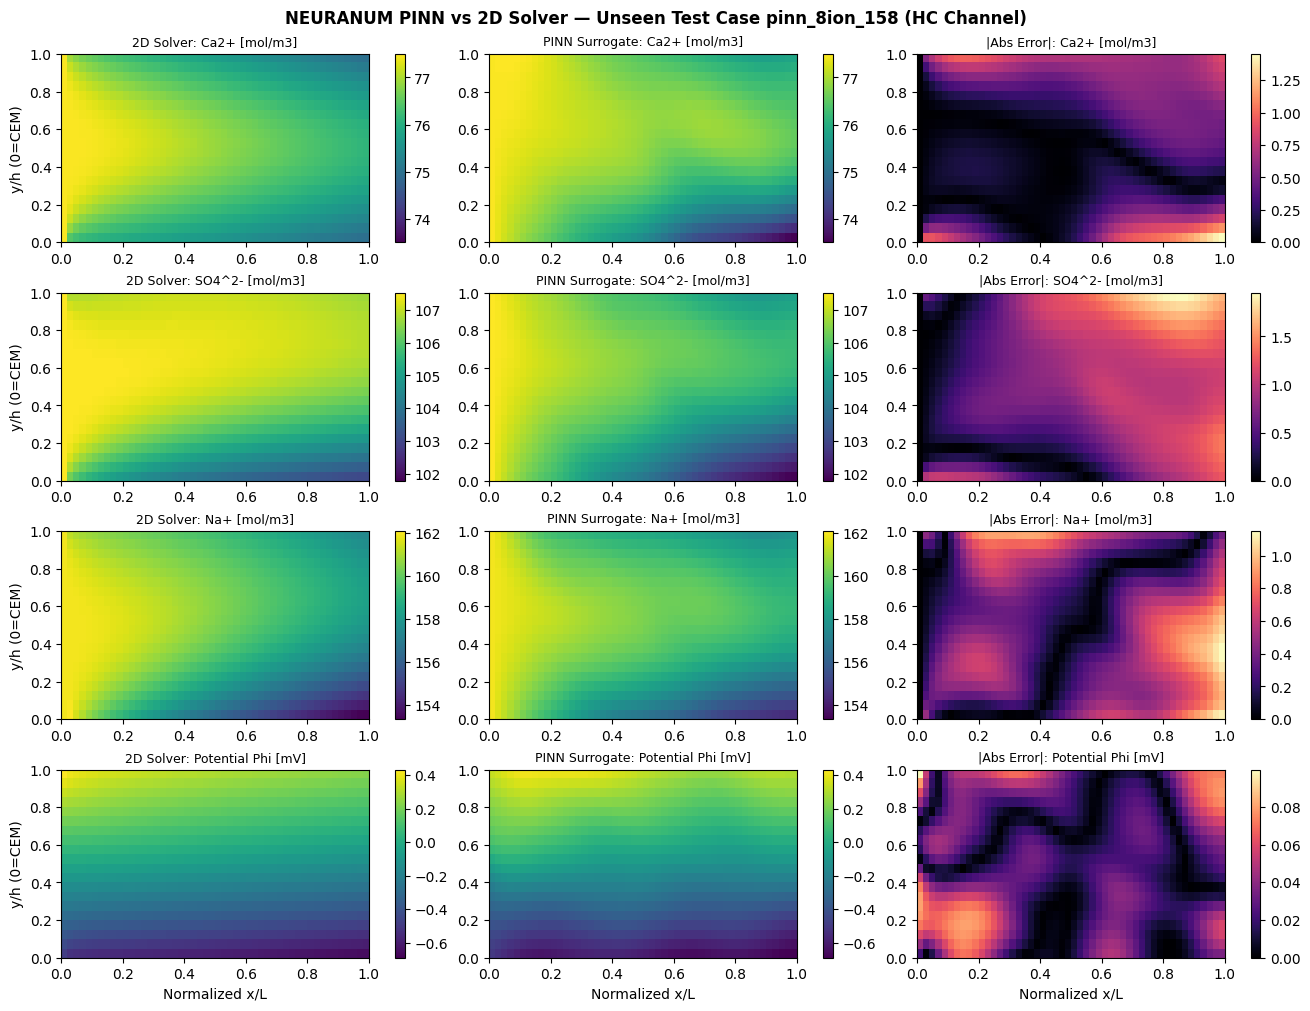

Calcite SI_max MAE (PINN+Pitzer vs Solver): 0.0020 SI units
Gypsum  SI_max MAE (PINN+Pitzer vs Solver): 0.0007 SI units
Scaling Risk Category (A/B/C) Test Accuracy: 100.0% (42/42)


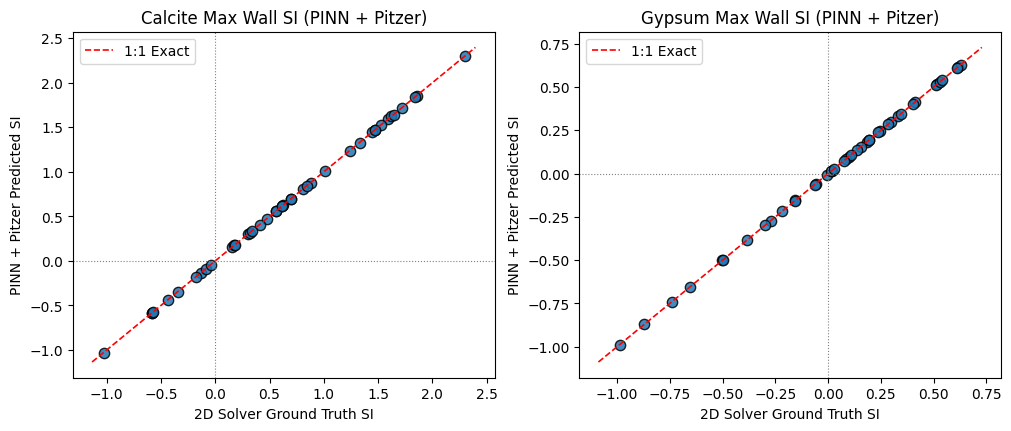

In [14]:
# Cell 7 — 2D Field Visualization & End-to-End Scaling/Fouling Risk Prediction (PINN -> Pitzer + CNT)
import math, os
import numpy as np
import matplotlib.pyplot as plt
import torch

# Compact USGS PHREEQC pitzer.dat parameters for the 8-ion NEURANUM system
PITZER_8ION_DB = {
    "rx": {
        "CO3-2 + H+ = HCO3-": [107.8871, 0.03252849, -5151.79, -38.92561, 563713.9],
        "CO3-2 + 2 H+ = CO2 + H2O": [464.1965, 0.09344813, -26986.16, -165.75951, 2248628.9],
        "SO4-2 + H+ = HSO4-": [-56.889, 0.006473, 2307.9, 19.8858],
        "Mg+2 + CO3-2 = MgCO3": [-32.225, 0.0, 1093.486, 12.72433],
    },
    "ph": {
        "Calcite": {"log_k": -8.44, "an": [-67.278, -0.050767, 0.0, 29.8956]},
        "Gypsum": {"log_k": -4.58},
    },
    "B0": {"Ca+2|Cl-":[0.3159,0,0,-0.000327,1.4e-7],"Ca+2|HCO3-":[0.4],"Ca+2|HSO4-":[0.2145],"Ca+2|OH-":[-0.1747],"Ca+2|SO4-2":[0.0],"Cl-|H+":[0.1775,0,0,-0.0003081],"Cl-|K+":[0.04808,-758.48,-4.7062,0.010072,-3.7599e-6],"Cl-|Mg+2":[0.351,0,0,-0.000932,5.94e-7],"Cl-|Na+":[0.07534,9598.4,35.48,-0.058731,1.798e-5,-500000.0],"CO3-2|K+":[0.1488,0,0,0.001788],"CO3-2|Na+":[0.0399,0,0,0.00179],"H+|HSO4-":[0.2065],"H+|SO4-2":[0.0298],"HCO3-|K+":[0.0296,0,0,0.000996],"HCO3-|Mg+2":[0.329],"HCO3-|Na+":[-0.018,0,0,-0.00023],"HSO4-|K+":[-0.0003],"HSO4-|Mg+2":[0.4746],"HSO4-|Na+":[0.0454],"K+|OH-":[0.1298],"K+|SO4-2":[0.0317,0,0,0.000928],"Mg+2|SO4-2":[0.2135,-951.0,0,-0.0234,2.28e-5],"Na+|OH-":[0.0864,0,0,0.0007],"Na+|SO4-2":[0.0273,0,-5.8,0.00989,0,-156300.0]},
    "B1": {"Ca+2|Cl-":[1.614,0,0,0.00763,-8.19e-7],"Ca+2|HCO3-":[2.977],"Ca+2|HSO4-":[2.53],"Ca+2|OH-":[-0.2303],"Ca+2|SO4-2":[3.546,0,0,0.00577],"Cl-|H+":[0.2945,0,0,0.0001419],"Cl-|K+":[0.2168,0,-6.895,0.02262,-9.293e-6,-100000.0],"Cl-|Mg+2":[1.65,0,0,-0.0109,2.6e-5],"Cl-|Na+":[0.2769,13770.0,46.8,-0.069512,2e-5,-748230.0],"CO3-2|K+":[1.43,0,0,0.002051],"CO3-2|Na+":[1.389,0,0,0.00205],"H+|HSO4-":[0.5556],"HCO3-|K+":[0.25,0,0,0.001104],"HCO3-|Mg+2":[0.6072],"HCO3-|Na+":[-0.0101,0,0,0.00172],"HSO4-|K+":[0.1735],"HSO4-|Mg+2":[1.729],"HSO4-|Na+":[0.398],"K+|OH-":[0.32],"K+|SO4-2":[0.756,-15140.0,-80.3,0.1091],"Mg+2|SO4-2":[3.367,-5780.0,0,-0.148,0.0001576],"Na+|OH-":[0.253,0,0,0.000134],"Na+|SO4-2":[0.956,2663.0,0,0.01158,0,-319400.0]},
    "B2": {"Ca+2|Cl-":[-1.13,0,0,-0.0476],"Ca+2|OH-":[-5.72],"Ca+2|SO4-2":[-59.3,0,0,-0.443,-3.96e-6],"HCO3-|Na+":[6.84,0,0,-0.00711],"Mg+2|SO4-2":[-32.45,0,-3236.0,21.812,-0.018859]},
    "C0": {"Ca+2|Cl-":[0.00014,-57.0,-0.098,-0.000783,7.18e-7],"Ca+2|SO4-2":[0.114],"Cl-|H+":[0.0008,0,0,6.213e-5],"Cl-|K+":[-0.000788,91.27,0.58643,-0.001298,4.9567e-7],"Cl-|Mg+2":[0.00651,0,0,-0.00025,2.418e-7],"Cl-|Na+":[0.00148,-120.5,-0.2081,0,1.166e-7,11121.0],"CO3-2|K+":[-0.0015],"CO3-2|Na+":[0.0044],"H+|SO4-2":[0.0438],"HCO3-|K+":[-0.008],"K+|OH-":[0.0041],"K+|SO4-2":[0.00818,-625.0,-3.3,0.00406],"Mg+2|SO4-2":[0.02875,0,-2.084,0.011428,-8.228e-6],"Na+|OH-":[0.0044,0,0,-0.0001894],"Na+|SO4-2":[0.003418,-384.0,0,-0.0008451,0,51770.0]},
    "THETA": {"Ca+2|H+":[0.092],"Ca+2|K+":[-0.00535,0,0,0.000308],"Ca+2|Mg+2":[0.007],"Ca+2|Na+":[0.0922,0,0,-0.000429,1.21e-6],"CO3-2|Cl-":[-0.02],"Cl-|HCO3-":[0.0512,0,0,-0.000481],"Cl-|HSO4-":[-0.006],"Cl-|OH-":[-0.05],"Cl-|SO4-2":[0.03],"CO3-2|OH-":[0.1],"CO3-2|SO4-2":[0.02],"H+|K+":[0.005],"H+|Mg+2":[0.1],"H+|Na+":[0.036],"CO3-2|HCO3-":[-0.04],"HCO3-|SO4-2":[0.01],"K+|Na+":[-0.012],"Mg+2|Na+":[0.07],"OH-|SO4-2":[-0.013]},
    "PSI": {"Ca+2|Cl-|H+":[-0.015],"Ca+2|Cl-|K+":[-0.025],"Ca+2|Cl-|Mg+2":[-0.012],"Ca+2|Cl-|Na+":[-0.0148,0,0,-5.2e-6],"Ca+2|Cl-|OH-":[-0.025],"Ca+2|Cl-|SO4-2":[-0.122,0,0,-0.00121],"Ca+2|K+|SO4-2":[-0.0365],"Ca+2|Mg+2|SO4-2":[0.024],"Ca+2|Na+|SO4-2":[-0.055,17.2],"CO3-2|Cl-|K+":[0.004],"CO3-2|Cl-|Na+":[0.0085],"Cl-|H+|K+":[-0.011],"Cl-|H+|Mg+2":[-0.011],"Cl-|H+|Na+":[-0.004],"Cl-|HCO3-|Mg+2":[-0.096],"Cl-|HCO3-|Na+":[-0.00473,0,0,0.000192],"Cl-|H+|HSO4-":[0.013],"Cl-|HSO4-|Na+":[-0.006],"Cl-|K+|Mg+2":[-0.022,-14.27],"Cl-|K+|Na+":[-0.0015,0,0,1.8e-5],"Cl-|K+|OH-":[-0.006],"Cl-|K+|SO4-2":[-0.001],"Cl-|Mg+2|Na+":[-0.012,-9.51],"Cl-|Mg+2|SO4-2":[-0.008,32.63],"Cl-|Na+|OH-":[-0.006],"Cl-|Na+|SO4-2":[0.0],"CO3-2|HCO3-|K+":[0.012],"CO3-2|HCO3-|Na+":[0.002],"CO3-2|K+|Na+":[0.003],"CO3-2|K+|OH-":[-0.01],"CO3-2|K+|SO4-2":[-0.009],"CO3-2|Na+|OH-":[-0.017],"CO3-2|Na+|SO4-2":[-0.005],"H+|HSO4-|K+":[-0.0265],"H+|HSO4-|Mg+2":[-0.0178],"H+|HSO4-|Na+":[-0.0129],"H+|K+|SO4-2":[0.197],"HCO3-|K+|Na+":[-0.003],"HCO3-|Mg+2|SO4-2":[-0.161],"HCO3-|Na+|SO4-2":[-0.005],"HSO4-|K+|SO4-2":[-0.0677],"HSO4-|Mg+2|SO4-2":[-0.0425],"HSO4-|Na+|SO4-2":[-0.0094],"K+|Mg+2|SO4-2":[-0.048],"K+|Na+|SO4-2":[-0.01],"K+|OH-|SO4-2":[-0.05],"Mg+2|Na+|SO4-2":[-0.015],"Na+|OH-|SO4-2":[-0.009]},
}
_ION_Z = {"H+":1,"Na+":1,"K+":1,"Mg+2":2,"Ca+2":2,"Cl-":-1,"HSO4-":-1,"HCO3-":-1,"OH-":-1,"SO4-2":-2,"CO3-2":-2,"MgCO3":0}
_MW = {"Na+":22.989769,"K+":39.0983,"Mg+2":24.305,"Ca+2":40.078,"Cl-":35.453,"SO4-2":96.0626,"HCO3-":61.0168,"CO3-2":60.0089}
_SP_MAP = {"Na":"Na+","K":"K+","Mg":"Mg+2","Ca":"Ca+2","Cl":"Cl-","SO4":"SO4-2","HCO3":"HCO3-","CO3":"CO3-2"}

def _p_param(blk, ions, T):
    c = PITZER_8ION_DB[blk].get("|".join(sorted(ions)))
    if not c: return 0.0
    c = (list(c) + [0]*6)[:6]
    if abs(T - 298.15) < 1e-9: return c[0]
    return c[0] + c[1]*(1/T - 1/298.15) + c[2]*math.log(T/298.15) + c[3]*(T-298.15) + c[4]*(T**2-298.15**2) + c[5]*(1/T**2-1/298.15**2)

def _logk(T, c, fb):
    a = (list(c) + [0]*6)[:6]
    return a[0] + a[1]*T + a[2]/T + a[3]*math.log10(T) + a[4]/T**2 + a[5]*T**2

def _a_phi(T):
    tc = T - 273.15
    rw = (999.83952+16.945176*tc-7.9870401e-3*tc**2-46.170461e-6*tc**3+105.56302e-9*tc**4-280.54253e-12*tc**5)/(1+16.87985e-3*tc)/1000.0
    U = [3.4279e2,-5.0866e-3,9.469e-7,-2.0525,3.1159e3,-1.8289e2,-8.0325e3,4.2142e6,2.1417]
    eps = U[0]*math.exp(U[1]*T+U[2]*T**2) + (U[3]+U[4]/(U[5]+T))*math.log((U[6]+U[7]/T+U[8]*T+1)/(U[6]+U[7]/T+U[8]*T+1000))
    return (1/3)*math.sqrt(2*math.pi*6.02214076e23*rw/1000.0)*((4.80320425e-10**2)/(eps*1.380649e-16*T))**1.5

def _pitzer_acts(m, T):
    m = {k:v for k,v in m.items() if v > 0}
    cats, anis = [k for k in m if _ION_Z[k] > 0], [k for k in m if _ION_Z[k] < 0]
    I = 0.5*sum((_ION_Z[k]**2)*v for k,v in m.items())
    if I <= 1e-12: return 1.0, {k:1.0 for k in m}
    sI, Z, Ap, b = math.sqrt(I), sum(abs(_ION_Z[k])*v for k,v in m.items()), _a_phi(T), 1.2
    pg = lambda x: 1.0 if x<1e-8 else 2*(1-(1+x)*math.exp(-x))/(x*x)
    pgp = lambda x: 0.0 if x<1e-8 else -2*(1-(1+x+0.5*x*x)*math.exp(-x))/(x*x)
    def pj(x):
        if x<=0: return 0.0,0.0
        u,v = x**-0.7237, x**0.528; ex = math.exp(-0.012*v); D = 4.0+4.581*u*ex
        return x/D, (D - x*(4.581*u*ex*(-0.7237-0.012*0.528*v)/x))/(D*D)
    def eth(z1,z2):
        if z1==z2 or z1==0 or z2==0: return 0.0,0.0
        x12,x11,x22 = 6*z1*z2*Ap*sI, 6*z1*z1*Ap*sI, 6*z2*z2*Ap*sI
        J12,Jp12 = pj(x12); J11,Jp11 = pj(x11); J22,Jp22 = pj(x22)
        e = (z1*z2/(4*I))*(J12 - 0.5*J11 - 0.5*J22)
        return e, -e/I + (z1*z2/(4*I))*(Jp12*0.5*x12/I - 0.5*Jp11*0.5*x11/I - 0.5*Jp22*0.5*x22/I)
    F = -Ap*(sI/(1+b*sI) + (2/b)*math.log(1+b*sI))
    B, Bp, C = {}, {}, {}
    for c in cats:
        zc = _ION_Z[c]
        for a in anis:
            za = abs(_ION_Z[a])
            b0,b1,b2,cp = _p_param("B0",[c,a],T), _p_param("B1",[c,a],T), _p_param("B2",[c,a],T), _p_param("C0",[c,a],T)
            x1 = (1.4 if zc==2 and za==2 else 2.0)*sI
            bv, bpv, bph = b0+b1*pg(x1), b1*pgp(x1)/I, b0+b1*math.exp(-x1)
            if abs(b2)>0: x2=12*sI; bv+=b2*pg(x2); bpv+=b2*pgp(x2)/I; bph+=b2*math.exp(-x2)
            B[c+"|"+a], Bp[c+"|"+a], C[c+"|"+a] = bv, bph, cp/(2*math.sqrt(zc*za))
            F += m[c]*m[a]*bpv
    Phcc, Pcc, Phaa, Paa = {}, [], {}, []
    for i in range(len(cats)):
        for j in range(i+1,len(cats)):
            c1,c2 = cats[i],cats[j]; e,ep = eth(_ION_Z[c1],_ION_Z[c2]); ph=_p_param("THETA",[c1,c2],T)+e
            Phcc[c1+"|"+c2]=Phcc[c2+"|"+c1]=ph; Pcc.append((c1,c2,ph+I*ep)); F+=m[c1]*m[c2]*ep
    for i in range(len(anis)):
        for j in range(i+1,len(anis)):
            a1,a2 = anis[i],anis[j]; e,ep = eth(_ION_Z[a1],_ION_Z[a2]); ph=_p_param("THETA",[a1,a2],T)+e
            Phaa[a1+"|"+a2]=Phaa[a2+"|"+a1]=ph; Paa.append((a1,a2,ph+I*ep)); F+=m[a1]*m[a2]*ep
    sCC = sum(m[c]*m[a]*C[c+"|"+a] for c in cats for a in anis)
    gam = {}
    for M in cats:
        lg = _ION_Z[M]**2*F + sum(m[a]*(2*B[M+"|"+a]+Z*C[M+"|"+a]) for a in anis)
        for cp in cats:
            if cp!=M: lg += m[cp]*(2*Phcc[M+"|"+cp]+sum(m[a]*_p_param("PSI",[M,cp,a],T) for a in anis))
        for i in range(len(anis)):
            for j in range(i+1,len(anis)): lg += m[anis[i]]*m[anis[j]]*_p_param("PSI",[M,anis[i],anis[j]],T)
        gam[M] = math.exp(lg + abs(_ION_Z[M])*sCC)
    for X in anis:
        zX = abs(_ION_Z[X])
        lg = zX**2*F + sum(m[c]*(2*B[c+"|"+X]+Z*C[c+"|"+X]) for c in cats)
        for ap in anis:
            if ap!=X: lg += m[ap]*(2*Phaa[X+"|"+ap]+sum(m[c]*_p_param("PSI",[c,X,ap],T) for c in cats))
        for i in range(len(cats)):
            for j in range(i+1,len(cats)): lg += m[cats[i]]*m[cats[j]]*_p_param("PSI",[cats[i],cats[j],X],T)
        gam[X] = math.exp(lg + zX*sCC)
    sm = sum(m.values())
    term = -(Ap*I**1.5)/(1+b*sI) + sum(m[c]*m[a]*(Bp[c+"|"+a]+Z*C[c+"|"+a]) for c in cats for a in anis)
    for c1,c2,pph in Pcc: term += m[c1]*m[c2]*(pph+sum(m[a]*_p_param("PSI",[c1,c2,a],T) for a in anis))
    for a1,a2,pph in Paa: term += m[a1]*m[a2]*(pph+sum(m[c]*_p_param("PSI",[c,a1,a2],T) for c in cats))
    return math.exp(-(1+2/max(sm,1e-30)*term)*0.01801528*sm), gam

def eval_pitzer_cnt_wall(c_wall_8, pH, T):
    tc = T - 273.15
    rho0 = (999.83952+16.945176*tc-7.9870401e-3*tc**2-46.170461e-6*tc**3)/(1+16.87985e-3*tc)/1000.0
    mp = {_SP_MAP[sp]: max(0.0, float(c_wall_8[i])) for i, sp in enumerate(SPECIES)}
    tds = sum((v/1000)*_MW[sp] for sp,v in mp.items())
    w_kg = max((rho0 + 0.72e-3*tds) - tds/1000.0, 0.5)
    mb = {sp: (v/1000.0)/w_kg for sp,v in mp.items() if v > 0}
    mw = dict(mb)
    rx = PITZER_8ION_DB["rx"]
    k2, k1, km, ks = 10**_logk(T,rx["CO3-2 + H+ = HCO3-"],10.329), 10**_logk(T,rx["CO3-2 + 2 H+ = CO2 + H2O"],16.6767), 10**_logk(T,rx["Mg+2 + CO3-2 = MgCO3"],2.928), 10**_logk(T,rx["SO4-2 + H+ = HSO4-"],1.988)
    dic, m_mg, m_so4, aH = mb.get("HCO3-",0)+mb.get("CO3-2",0), mb.get("Mg+2",0), mb.get("SO4-2",0), 10**(-pH)
    aw, g = _pitzer_acts(mw, T)
    for _ in range(8):
        if dic > 0:
            rh = k2*aH*(g.get("CO3-2",1)/max(g.get("HCO3-",1),1e-12))
            rc = (k1*aH**2*g.get("CO3-2",1))/max(aw,0.2)
            rm = km*g.get("Mg+2",1)*mw.get("Mg+2",m_mg)*g.get("CO3-2",1)
            co3f = dic/(1+rh+rc+rm)
            mw["CO3-2"], mw["HCO3-"] = co3f, rh*co3f
            mw["Mg+2"], mw["MgCO3"] = max(m_mg-rm*co3f,1e-12), rm*co3f
        if m_so4 > 0:
            rs = ks*aH*(g.get("SO4-2",1)/max(g.get("HSO4-",1),1e-12))
            mw["SO4-2"] = m_so4/(1+rs)
            if rs > 1e-6: mw["HSO4-"] = m_so4 - mw["SO4-2"]
            else: mw.pop("HSO4-", None)
        aw, g = _pitzer_acts(mw, T)
    om_cal = max(g.get("Ca+2",1)*mw.get("Ca+2",0)*g.get("CO3-2",1)*mw.get("CO3-2",0),1e-30)/(10**_logk(T,PITZER_8ION_DB["ph"]["Calcite"]["an"],-8.44))
    om_gyp = max(g.get("Ca+2",1)*mw.get("Ca+2",0)*g.get("SO4-2",1)*mw.get("SO4-2",0)*(aw**2),1e-30)/(10**PITZER_8ION_DB["ph"]["Gypsum"]["log_k"])
    return om_cal, om_gyp

def classify_cnt(om_cal, om_gyp, T, theta_deg, rough):
    cos_eff = max(-0.9999, min(0.9999, rough * math.cos(math.radians(theta_deg))))
    f_wet = 0.25 * (2.0 + cos_eff) * (1.0 - cos_eff)**2
    def rank_one(om, vm, gam):
        si = math.log10(max(om, 1e-30))
        if om <= 1.0:
            return 1 if si < -0.1 else 2
        dmu = 1.380649e-23 * T * math.log(om)
        bar = f_wet * (16*math.pi*(gam**3)*((vm/6.02214076e23)**2)/(3*dmu**2)) / (1.380649e-23*T)
        return 3 if bar <= 40.0 else 2
    r = max(rank_one(om_cal, 36.9e-6, 0.094), rank_one(om_gyp, 73.9e-6, 0.037))
    return {1: "Category A: Clean membrane", 2: "Category B: Scaling-risk condition", 3: "Category C: Nucleation-prone condition"}[r]

# --- Part A: 2D Heatmap Comparison on an Unseen Test Case (HC Channel) ---
if "test_ds" not in globals():
    test_ds = Neuranum8IonDataset(test_df, param_scaler)
if "model" not in globals():
    model = FourierRedPINN(param_dim=len(PARAM_COLS), n_species=8, hidden=128, layers=4, fourier_dim=16).to(DEVICE)
model.load_state_dict(torch.load("/content/drive/MyDrive/NEURANUM/neuranum_pinn_8ion.pt", map_location=DEVICE))
model.eval()

hc_recs = {rec["case_id"]: rec for rec in test_ds if rec["ch_flag"][0, 0] > 0.5}
sample_row = test_df.sort_values("si_gypsum_cem_max", ascending=False).iloc[0]
rec = hc_recs[sample_row["case_id"]]

with torch.no_grad():
    c_t, phi_t = model(
        torch.tensor(rec["xy_tilde"], device=DEVICE),
        torch.tensor(rec["ch_flag"], device=DEVICE),
        torch.tensor(rec["params_norm"], device=DEVICE),
        torch.tensor(rec["c_inlet"], device=DEVICE),
        torch.tensor(rec["c_scale"], device=DEVICE),
    )
V_T = (8.314462618 * rec["T"][0, 0]) / 96485.33212
c_pred_2d = (c_t.cpu().numpy() * rec["c_scale"]).reshape(50, 20, 8)
c_true_2d = rec["c_true"].reshape(50, 20, 8)
phi_pred_mv = (phi_t.cpu().numpy() * V_T * 1000.0).reshape(50, 20)
phi_true_mv = (rec["phi_true"] * 1000.0).reshape(50, 20)

panels = [
    ("Ca2+ [mol/m3]", c_true_2d[:, :, 3], c_pred_2d[:, :, 3]),
    ("SO4^2- [mol/m3]", c_true_2d[:, :, 5], c_pred_2d[:, :, 5]),
    ("Na+ [mol/m3]", c_true_2d[:, :, 0], c_pred_2d[:, :, 0]),
    ("Potential Phi [mV]", phi_true_mv, phi_pred_mv),
]
fig, axes = plt.subplots(4, 3, figsize=(13, 10), constrained_layout=True)
for r_i, (label, t2d, p2d) in enumerate(panels):
    vmin, vmax = min(t2d.min(), p2d.min()), max(t2d.max(), p2d.max())
    err2d = np.abs(p2d - t2d)
    for c_i, (arr, ttl, cmap, lo, hi) in enumerate([
        (t2d.T, f"2D Solver: {label}", "viridis", vmin, vmax),
        (p2d.T, f"PINN Surrogate: {label}", "viridis", vmin, vmax),
        (err2d.T, f"|Abs Error|: {label}", "magma", 0.0, max(err2d.max(), 1e-6)),
    ]):
        im = axes[r_i, c_i].imshow(arr, origin="lower", aspect="auto", extent=[0, 1, 0, 1], cmap=cmap, vmin=lo, vmax=hi)
        axes[r_i, c_i].set_title(ttl, fontsize=9)
        if r_i == 3: axes[r_i, c_i].set_xlabel("Normalized x/L")
        if c_i == 0: axes[r_i, c_i].set_ylabel("y/h (0=CEM)")
        fig.colorbar(im, ax=axes[r_i, c_i], fraction=0.046)

fig.suptitle(f"NEURANUM PINN vs 2D Solver — Unseen Test Case {sample_row['case_id']} (HC Channel)", fontsize=12, fontweight="bold")
out_dir = "/content/drive/MyDrive/NEURANUM"
os.makedirs(out_dir, exist_ok=True)
fig.savefig(os.path.join(out_dir, "neuranum_pinn_2d_comparison.png"), dpi=300)
plt.show()

# --- Part B: CEM Wall Scaling Risk Prediction (PINN -> Pitzer SI + CNT) across All Unseen Test Cases ---
si_cal_true, si_cal_pinn, si_gyp_true, si_gyp_pinn = [], [], [], []
cat_matches = []
for _, row in test_df.iterrows():
    r_hc = hc_recs[row["case_id"]]
    with torch.no_grad():
        c_t, _ = model(
            torch.tensor(r_hc["xy_tilde"], device=DEVICE),
            torch.tensor(r_hc["ch_flag"], device=DEVICE),
            torch.tensor(r_hc["params_norm"], device=DEVICE),
            torch.tensor(r_hc["c_inlet"], device=DEVICE),
            torch.tensor(r_hc["c_scale"], device=DEVICE),
        )
    c_wall_line = (c_t.cpu().numpy() * r_hc["c_scale"]).reshape(50, 20, 8)[:, 0, :]  # y=0 CEM wall
    om_c_max, om_g_max = 0.0, 0.0
    for ix in range(50):
        oc, og = eval_pitzer_cnt_wall(c_wall_line[ix], float(row["pH"]), float(row["temperature_K"]))
        om_c_max, om_g_max = max(om_c_max, oc), max(om_g_max, og)
    si_cal_pinn.append(math.log10(max(om_c_max, 1e-30)))
    si_gyp_pinn.append(math.log10(max(om_g_max, 1e-30)))
    si_cal_true.append(float(row["si_calcite_cem_max"]))
    si_gyp_true.append(float(row["si_gypsum_cem_max"]))
    cat_pred = classify_cnt(om_c_max, om_g_max, float(row["temperature_K"]), float(row["contact_angle_cem_deg"]), float(row["roughness_factor_cem"]))
    cat_matches.append(cat_pred == row["dominant_scaling_category"])

print(f"Calcite SI_max MAE (PINN+Pitzer vs Solver): {np.mean(np.abs(np.array(si_cal_pinn)-np.array(si_cal_true))):.4f} SI units")
print(f"Gypsum  SI_max MAE (PINN+Pitzer vs Solver): {np.mean(np.abs(np.array(si_gyp_pinn)-np.array(si_gyp_true))):.4f} SI units")
print(f"Scaling Risk Category (A/B/C) Test Accuracy: {np.mean(cat_matches)*100:.1f}% ({sum(cat_matches)}/{len(cat_matches)})")

fig2, ax2 = plt.subplots(1, 2, figsize=(10, 4.2), constrained_layout=True)
for ax, xt, yp, ttl in [
    (ax2[0], si_cal_true, si_cal_pinn, "Calcite Max Wall SI (PINN + Pitzer)"),
    (ax2[1], si_gyp_true, si_gyp_pinn, "Gypsum Max Wall SI (PINN + Pitzer)"),
]:
    lo, hi = min(min(xt), min(yp)) - 0.1, max(max(xt), max(yp)) + 0.1
    ax.scatter(xt, yp, s=55, alpha=0.85, edgecolor="k")
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.2, label="1:1 Exact")
    ax.axhline(0, color="gray", lw=0.8, ls=":"); ax.axvline(0, color="gray", lw=0.8, ls=":")
    ax.set_xlabel("2D Solver Ground Truth SI"); ax.set_ylabel("PINN + Pitzer Predicted SI")
    ax.set_title(ttl); ax.legend()
fig2.savefig(os.path.join(out_dir, "neuranum_pinn_scaling_parity.png"), dpi=300)
plt.show()